In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ==========================================
# 1. PARAMETERS & CONFIGURATION
# ==========================================
CSV_PATH = "riboflavin_features_new.csv"  # Target your pre-extracted features file
CONC_COLUMN = "label"                     # Column keeping track of concentration folders
FILE_COLUMN = "filename"                  # Column tracking raw image filenames

print(f"📖 Loading extracted feature array map from '{CSV_PATH}'...")
df_features = pd.read_csv(CSV_PATH)

# Clean up structural trailing whitespaces from parsing strings if any exist
df_features.columns = df_features.columns.str.strip()

# 🛡️ FIX: DROP MISSING VALUES GLOBAL CHECKPOINT
initial_row_count = len(df_features)
df_features = df_features.dropna()
cleaned_row_count = len(df_features)

dropped_rows = initial_row_count - cleaned_row_count
if dropped_rows > 0:
    print(f"⚠️ Cleaned {dropped_rows} rows from dataset containing missing/NaN visual feature anomalies.")

# Safely parse concentration variables
df_features[CONC_COLUMN] = df_features[CONC_COLUMN].astype(float)

# Isolate all numerical metrics for high-dimensional distance geometry processing
non_feature_cols = [FILE_COLUMN, CONC_COLUMN]
feature_columns = [col for col in df_features.columns if col not in non_feature_cols]

print(f"📊 Matrix configuration identified: {len(df_features)} samples across {len(feature_columns)} geometric descriptors.")

# ==========================================
# 2. UNSUPERVISED DISCOVERY ENGINE
# ==========================================
print("\n🔮 Running mathematical clustering sweeps across concentration bounds...")
df_features["sub_morphology_cluster"] = 0

# Track processing scores across active loops
concentration_profiles = sorted(df_features[CONC_COLUMN].unique())

for conc in concentration_profiles:
    subset_mask = df_features[CONC_COLUMN] == conc
    subset_idx = df_features[subset_mask].index
    
    # Validation safety checkpoint
    if len(subset_idx) < 4:
        print(f" ⚠️ Concentration {conc:.1f} ppm: Insufficient sample count ({len(subset_idx)}) for reliable cluster maps.")
        continue
        
    # Extract the vector array slice for this concentration sub-population
    X = df_features.loc[subset_idx, feature_columns].values
    
    # Scale feature dimensions to neutralize scale dominance metrics 
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    best_k = 1
    best_score = -1
    
    # Sweep cluster configurations to seek true visual variants
    for k in [2, 3]:
        if len(X_scaled) > k:
            km = KMeans(n_clusters=k, random_state=42, n_init=10)
            labels = km.fit_predict(X_scaled)
            score = silhouette_score(X_scaled, labels)
            
            if score > best_score:
                best_score = score
                best_k = k
                
    # Evaluation gate: Only split if morphology sub-clusters show clear separation boundaries
    if best_k > 1 and best_score > 0.22:
        print(f"  🎯 Concentration {conc:.1f} ppm -> Split into {best_k} distinct morphology categories (Silhouette: {best_score:.3f})")
        final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
        df_features.loc[subset_idx, "sub_morphology_cluster"] = final_km.fit_predict(X_scaled)
    else:
        print(f"  🧊 Concentration {conc:.1f} ppm -> Unified as 1 morphology type (Highly uniform structures, Silhouette: {best_score:.3f})")

# ==========================================
# 3. VERIFICATION REPORT LOGGING
# ==========================================
print("\n" + "="*55)
print("📊 SUB-MORPHOLOGY CATEGORY SPLIT OVERVIEW")
print("="*55)
distribution_report = df_features.groupby([CONC_COLUMN, "sub_morphology_cluster"]).size()
print(distribution_report.to_string(header=["Sample Count"]))
print("="*55)

print("\n📋 Top lines snippet matching verification vectors:")
preview_cols = [FILE_COLUMN, CONC_COLUMN, "sub_morphology_cluster", "area_fraction", "fractal_dim"]
available_preview = [col for col in preview_cols if col in df_features.columns]
print(df_features[available_preview].head(10).to_string(index=False))

📖 Loading extracted feature array map from 'riboflavin_features_new.csv'...
⚠️ Cleaned 295 rows from dataset containing missing/NaN visual feature anomalies.
📊 Matrix configuration identified: 2813 samples across 61 geometric descriptors.

🔮 Running mathematical clustering sweeps across concentration bounds...
  🎯 Concentration 1.0 ppm -> Split into 2 distinct morphology categories (Silhouette: 0.296)
  🎯 Concentration 6.0 ppm -> Split into 2 distinct morphology categories (Silhouette: 0.399)
  🎯 Concentration 12.5 ppm -> Split into 2 distinct morphology categories (Silhouette: 0.341)
  🎯 Concentration 25.0 ppm -> Split into 3 distinct morphology categories (Silhouette: 0.353)
  🎯 Concentration 50.0 ppm -> Split into 2 distinct morphology categories (Silhouette: 0.283)
  🧊 Concentration 100.0 ppm -> Unified as 1 morphology type (Highly uniform structures, Silhouette: 0.192)

📊 SUB-MORPHOLOGY CATEGORY SPLIT OVERVIEW
label  sub_morphology_cluster
1.0    0                         166
    

🎨 Generating visual audit plots for discovered sub-morphologies...


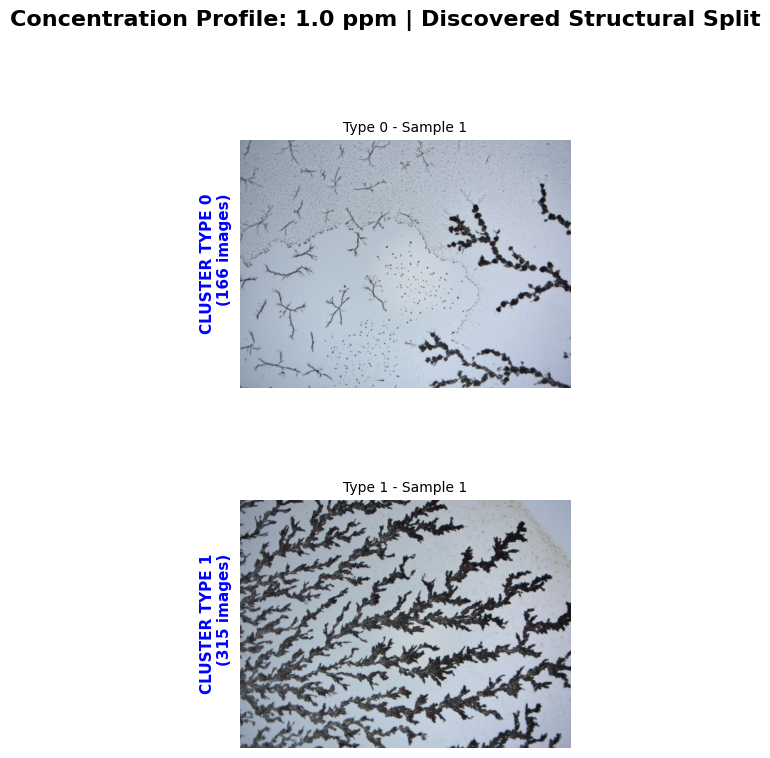


--------------------------------------------------------------------------------



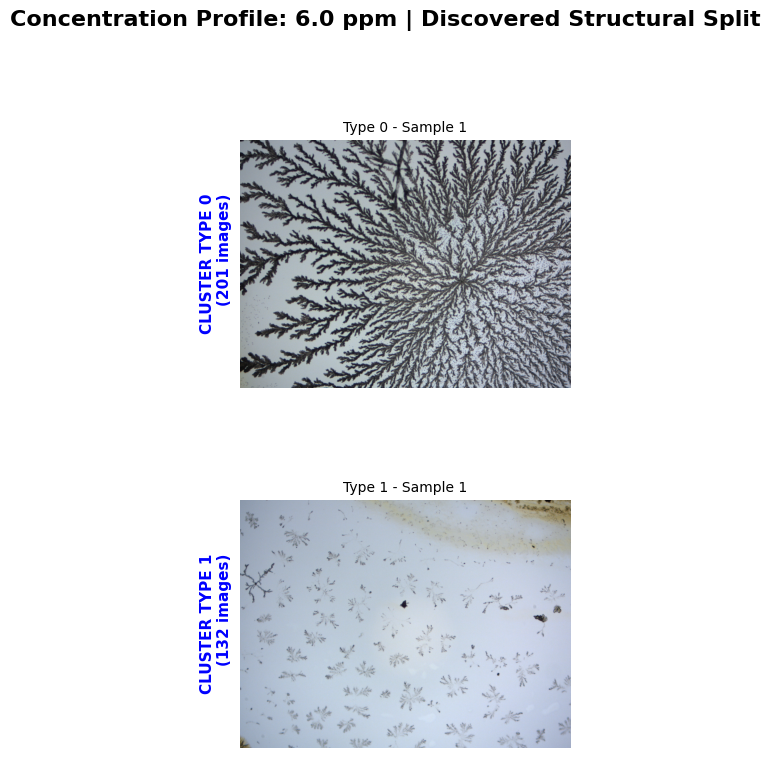


--------------------------------------------------------------------------------



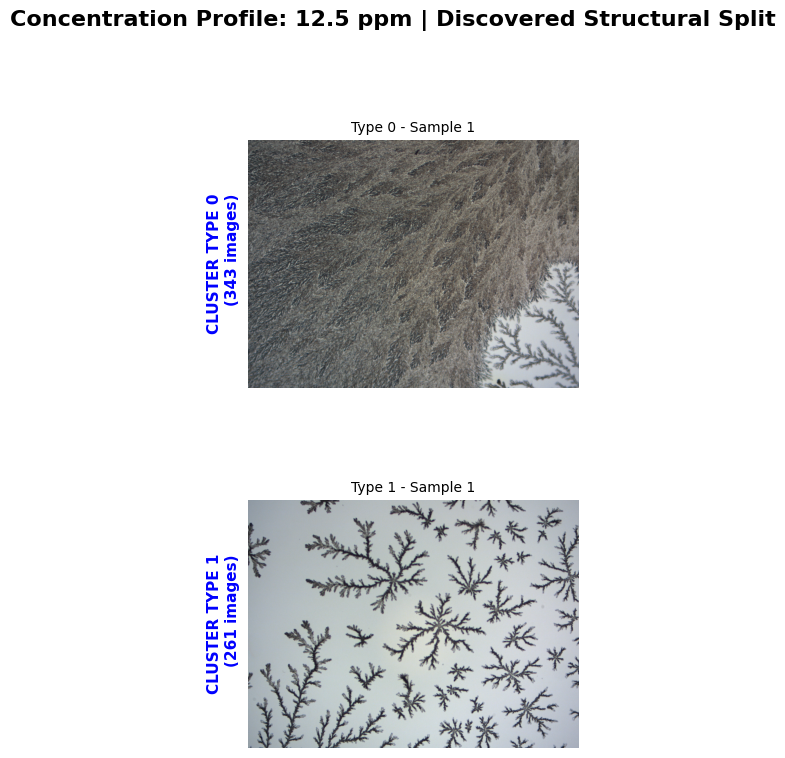


--------------------------------------------------------------------------------



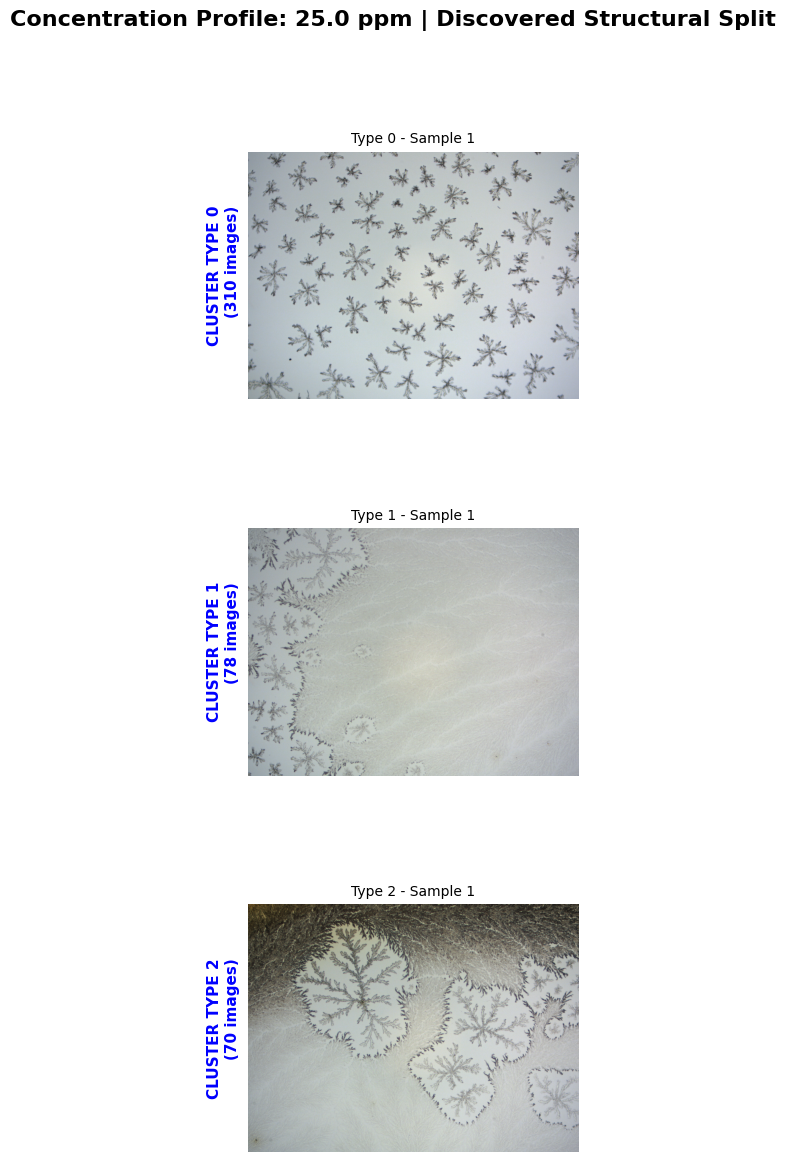


--------------------------------------------------------------------------------



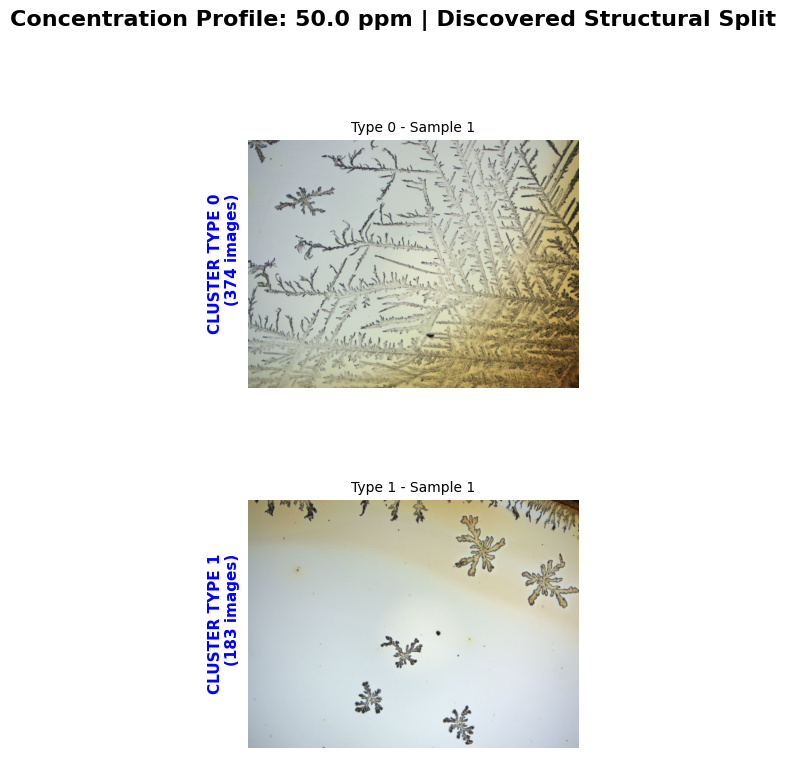


--------------------------------------------------------------------------------



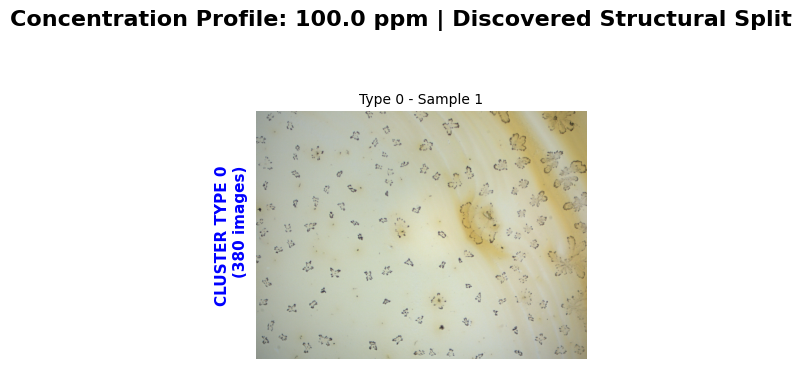


--------------------------------------------------------------------------------



In [3]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# --- CONFIGURATION ---
RAW_DATA_DIR = "./New_Riboflavin_Data"       # Path to your raw nested folders (1, 6, 12.5...)
CONC_COLUMN = "label"                        # Column name for concentrations
FILE_COLUMN = "filename"                     # Column name for filenames
CLUSTER_COLUMN = "sub_morphology_cluster"    # The newly created cluster assignment column
SAMPLES_PER_CLUSTER = 1                     # Number of example images to inspect per row
# ---------------------

# Format concentration labels nicely to match folder tracking strings
unique_concs = sorted(df_features[CONC_COLUMN].unique())

print("🎨 Generating visual audit plots for discovered sub-morphologies...")

for conc in unique_concs:
    # Handle matching the directory name whether it's integer-string or float-string style
    # Checks both "12.5" and "1" style matches
    folder_name = f"{conc:.1f}" if conc % 1 != 0 else f"{int(conc)}"
    folder_path = os.path.join(RAW_DATA_DIR, folder_name)
    
    # Fallback defense if path string styles differ
    if not os.path.exists(folder_path):
        folder_name = f"{conc:.1f}"
        folder_path = os.path.join(RAW_DATA_DIR, folder_name)
        
    df_slice = df_features[df_features[CONC_COLUMN] == conc]
    discovered_clusters = sorted(df_slice[CLUSTER_COLUMN].unique())
    num_clusters = len(discovered_clusters)
    
    # Create an adjusted grid subplot system for this concentration step
    fig, axes = plt.subplots(num_clusters, SAMPLES_PER_CLUSTER, 
                             figsize=(4 * SAMPLES_PER_CLUSTER, 4 * num_clusters), 
                             squeeze=False)
    
    plt.suptitle(f"Concentration Profile: {conc} ppm | Discovered Structural Split", 
                 fontsize=16, weight='bold', y=1.02)
    
    for row_idx, cluster_id in enumerate(discovered_clusters):
        df_cluster = df_slice[df_slice[CLUSTER_COLUMN] == cluster_id]
        cluster_count = len(df_cluster)
        
        # Grab a random selection of images from this cluster to inspect variance
        sample_pool = df_cluster[FILE_COLUMN].tolist()
        num_to_draw = min(SAMPLES_PER_CLUSTER, len(sample_pool))
        selected_samples = random.sample(sample_pool, num_to_draw)
        
        for col_idx in range(SAMPLES_PER_CLUSTER):
            ax = axes[row_idx, col_idx]
            
            if col_idx < len(selected_samples):
                img_name = selected_samples[col_idx]
                img_path = os.path.join(folder_path, img_name)
                
                try:
                    with Image.open(img_path) as img:
                        # Convert to grayscale for display matching
                        ax.imshow(img, cmap='gray')
                    ax.set_title(f"Type {cluster_id} - Sample {col_idx+1}", fontsize=10)
                except Exception as e:
                    ax.text(0.5, 0.5, f"Error Loading\n{img_name}", 
                            ha='center', va='center', color='red', fontsize=8)
            else:
                # Padding blank boxes if the cluster size is tiny
                ax.text(0.5, 0.5, "No Data", ha='center', va='center', color='gray')
                
            ax.axis('off')
            
        # Label rows with the cluster type and sample weight density
        axes[row_idx, 0].text(-25, axes[row_idx, 0].get_ylim()[0]/2, 
                              f"CLUSTER TYPE {cluster_id}\n({cluster_count} images)", 
                              rotation=90, va='center', ha='right', weight='bold', fontsize=11, color='blue')

    plt.tight_layout()
    plt.show()
    print("\n" + "-"*80 + "\n")

In [4]:
import os
import json
import shutil
from tqdm import tqdm

# --- CONFIGURATION ---
RAW_DATA_DIR = "./New_Riboflavin_Data"         # Path to your raw nested folders
MASTER_TRAIN_DIR = "./new_riboflavin_train_ready"
CONC_COLUMN = "label"                          # Column name for concentrations in df_features
FILE_COLUMN = "filename"                       # Column name for filenames in df_features
CLUSTER_COLUMN = "sub_morphology_cluster"      # The new cluster assignment column
# ---------------------

print(f"📦 Preparing clean slate for sub-labeled dataset at: '{MASTER_TRAIN_DIR}'...")

# Reset master training directory
if os.path.exists(MASTER_TRAIN_DIR):
    shutil.rmtree(MASTER_TRAIN_DIR)
os.makedirs(MASTER_TRAIN_DIR, exist_ok=True)

master_metadata_path = os.path.join(MASTER_TRAIN_DIR, "metadata.jsonl")
image_count = 0

print("\n🚀 Indexing clustered dataframe records and mapping files...")

with open(master_metadata_path, 'w') as f_master:
    # Iterate through every row in your verified features dataframe
    for idx, row in tqdm(df_features.iterrows(), total=len(df_features), desc="Compiling Dataset"):
        raw_filename = row[FILE_COLUMN]
        conc_val = float(row[CONC_COLUMN])
        cluster_id = int(row[CLUSTER_COLUMN])
        
        # 1. Normalize concentration string formatting to match raw folders safely
        # Checks both "12.5" and "1" style naming variants
        folder_name = f"{conc_val:.1f}" if conc_val % 1 != 0 else f"{int(conc_val)}"
        src_folder_path = os.path.join(RAW_DATA_DIR, folder_name)
        
        # Fallback tracking check
        if not os.path.exists(src_folder_path):
            folder_name = f"{conc_val:.1f}"
            src_folder_path = os.path.join(RAW_DATA_DIR, folder_name)
            
        src_image_path = os.path.join(src_folder_path, raw_filename)
        
        # Verify file presence before trying to copy
        if not os.path.exists(src_image_path):
            continue
            
        # 2. Setup standard string conversion for downstream regex consistency ("1.0", "12.5", etc.)
        clean_conc_str = f"{conc_val:.1f}"
        
        # 3. Namespace target filename with concentration and discovered visual type
        unique_filename = f"conc_{clean_conc_str}_type_{cluster_id}_{raw_filename}"
        dst_image_path = os.path.join(MASTER_TRAIN_DIR, unique_filename)
        
        # 4. Copy image asset over
        shutil.copy2(src_image_path, dst_image_path)
        
        # 5. Inject explicit morphological subclass tokens into training text caption
        caption_text = f"a microscopic photo of a ribo_crystal crystallization, concentration {clean_conc_str}, type_{cluster_id} morphology"
        
        # 6. Build entry and append line to tracking jsonl manifest
        metadata_entry = {"file_name": unique_filename, "text": caption_text}
        f_master.write(json.dumps(metadata_entry) + "\n")
        image_count += 1

print(f"\n✨ Done! Master train dataset successfully built.")
print(f"Total structured images output: {image_count}")
print(f"Tracking Manifest File: {master_metadata_path}")

📦 Preparing clean slate for sub-labeled dataset at: './new_riboflavin_train_ready'...

🚀 Indexing clustered dataframe records and mapping files...


Compiling Dataset: 100%|████████████████████████████████████████████████████████| 2813/2813 [01:07<00:00, 41.93it/s]


✨ Done! Master train dataset successfully built.
Total structured images output: 2813
Tracking Manifest File: ./new_riboflavin_train_ready/metadata.jsonl
